In [1]:
!pip -q install timm huggingface_hub

In [21]:
from huggingface_hub import snapshot_download
import os
import glob
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
from collections import Counter
import random
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm
import torch.nn as nn

from google.colab import files

In [4]:
dataset_path = snapshot_download(
    repo_id="NMFS-OSI/NOAA-PIFSC-ESD-CORAL-Bleaching-Dataset",
    repo_type="dataset"
)
print("Dataset saved at:", dataset_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10422 files:   0%|          | 0/10422 [00:00<?, ?it/s]

Dataset saved at: /root/.cache/huggingface/hub/datasets--NMFS-OSI--NOAA-PIFSC-ESD-CORAL-Bleaching-Dataset/snapshots/8175d66ef0346795ace415b8b3950ee612ae1463


In [7]:
for folder, subfolders, files in os.walk(dataset_path):
    level = folder.replace(dataset_path, "").count(os.sep)
    if level <= 2:
        print("  " * level + os.path.basename(folder) + f"/  ({len(files)} files)")

8175d66ef0346795ace415b8b3950ee612ae1463/  (3 files)
  val/  (0 files)
    CORAL_BL/  (589 files)
    CORAL/  (973 files)
  test/  (0 files)
    CORAL_BL/  (591 files)
    CORAL/  (974 files)
  train/  (0 files)
    CORAL_BL/  (2751 files)
    CORAL/  (4541 files)


In [8]:
image_extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

all_images = []
for path in glob.glob(dataset_path + "/**/*", recursive=True):
    if path.lower().endswith(image_extensions):
        all_images.append(path)

# Label of each image = name of the folder it is in
all_labels = [os.path.basename(os.path.dirname(p)) for p in all_images]

class_names = sorted(set(all_labels))
name_to_number = {name: i for i, name in enumerate(class_names)}
all_label_numbers = [name_to_number[name] for name in all_labels]

print("Classes:", class_names)
print("Total images:", len(all_images))

train_images, val_images, train_labels, val_labels = train_test_split(
    all_images, all_label_numbers,
    test_size=0.2,
    stratify=all_label_numbers,
    random_state=42
)
print("Train:", len(train_images), "| Val:", len(val_images))

Classes: ['CORAL', 'CORAL_BL']
Total images: 10419
Train: 8335 | Val: 2084


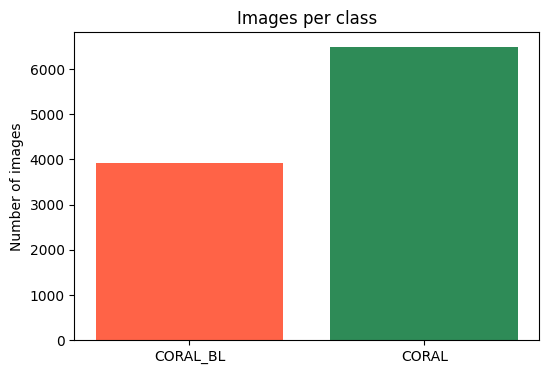

In [9]:
counts = Counter(all_labels)
plt.figure(figsize=(6, 4))
plt.bar(counts.keys(), counts.values(), color=["tomato", "seagreen", "gold", "skyblue"][:len(counts)])
plt.title("Images per class")
plt.ylabel("Number of images")
plt.show()

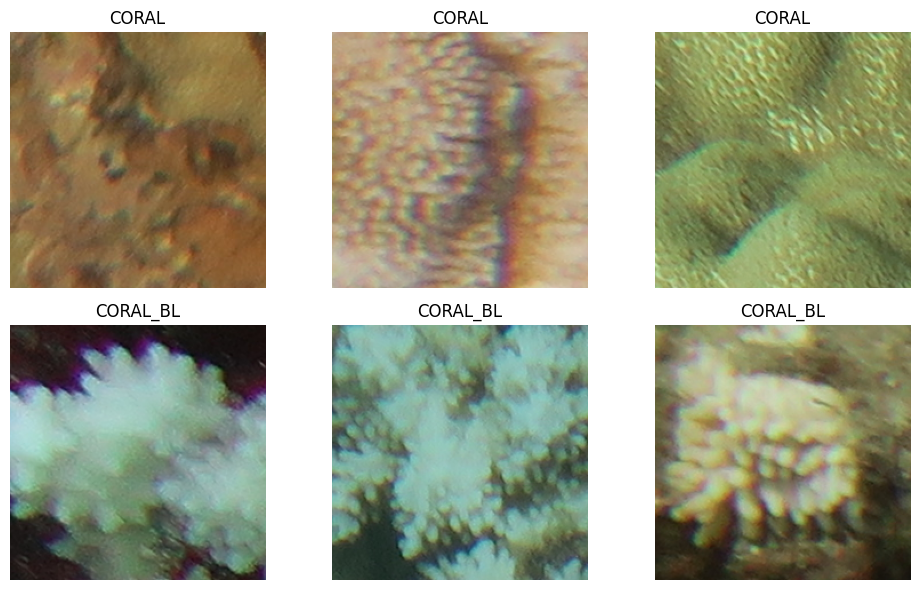

In [10]:
fig, axes = plt.subplots(len(class_names), 3, figsize=(10, 3 * len(class_names)))
axes = axes.reshape(len(class_names), 3)

for row, name in enumerate(class_names):
    class_images = [p for p, l in zip(all_images, all_labels) if l == name]
    chosen = random.sample(class_images, min(3, len(class_images)))
    for col, path in enumerate(chosen):
        axes[row, col].imshow(Image.open(path).convert("RGB"))
        axes[row, col].set_title(name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [11]:
mean = (0.485, 0.456, 0.406)
std = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class CoralDataset(Dataset):
    def __init__(self, image_paths, labels, transform):
        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image = Image.open(self.image_paths[index]).convert("RGB")
        image = self.transform(image)
        return image, self.labels[index]

train_loader = DataLoader(CoralDataset(train_images, train_labels, train_transform),
                          batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(CoralDataset(val_images, val_labels, val_transform),
                        batch_size=64, shuffle=False, num_workers=4, pin_memory=True)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [13]:
device = "cuda"

model = timm.create_model("convnext_tiny", pretrained=True, num_classes=len(class_names))
model = model.to(device)

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

In [14]:
EPOCHS = 10

loss_function = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=0.05)
scheduler = torch.optim.lr_scheduler.OneCycleLR(
    optimizer, max_lr=2e-4, total_steps=EPOCHS * len(train_loader)
)
scaler = torch.amp.GradScaler("cuda")

best_accuracy = 0
train_losses = []
val_accuracies = []

for epoch in range(EPOCHS):

    # ---- Training ----
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        with torch.autocast("cuda", dtype=torch.float16):
            predictions = model(images)
            loss = loss_function(predictions, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        total_loss += loss.item()

    # ---- Validation ----
    model.eval()
    correct = 0
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        for images, labels in val_loader:
            images = images.to(device)
            predicted_class = model(images).argmax(dim=1).cpu()
            correct += (predicted_class == labels).sum().item()

    accuracy = correct / len(val_images)
    avg_loss = total_loss / len(train_loader)
    train_losses.append(avg_loss)
    val_accuracies.append(accuracy)

    print(f"Epoch {epoch+1}/{EPOCHS}  |  Loss: {avg_loss:.4f}  |  Val accuracy: {accuracy:.4f}")

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        torch.save(model.state_dict(), "best_model.pt")

print("Best accuracy:", best_accuracy)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
/tmp/ipykernel_1103/3385189420.py:30: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


Epoch 1/10  |  Loss: 0.4454  |  Val accuracy: 0.8129
Epoch 2/10  |  Loss: 0.4003  |  Val accuracy: 0.8628
Epoch 3/10  |  Loss: 0.3968  |  Val accuracy: 0.8661
Epoch 4/10  |  Loss: 0.3851  |  Val accuracy: 0.8762
Epoch 5/10  |  Loss: 0.3752  |  Val accuracy: 0.8930
Epoch 6/10  |  Loss: 0.3608  |  Val accuracy: 0.8901
Epoch 7/10  |  Loss: 0.3438  |  Val accuracy: 0.8762
Epoch 8/10  |  Loss: 0.3166  |  Val accuracy: 0.8920
Epoch 9/10  |  Loss: 0.2833  |  Val accuracy: 0.8925
Epoch 10/10  |  Loss: 0.2609  |  Val accuracy: 0.8916
Best accuracy: 0.8929942418426103


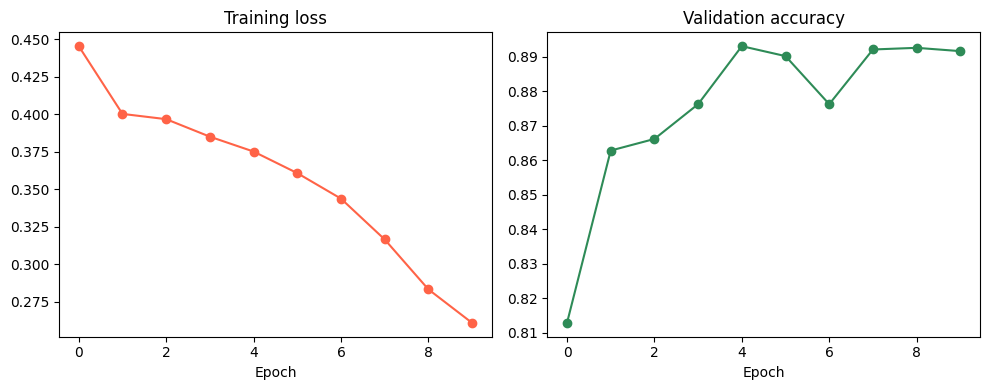

In [15]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, marker="o", color="tomato")
plt.title("Training loss")
plt.xlabel("Epoch")

plt.subplot(1, 2, 2)
plt.plot(val_accuracies, marker="o", color="seagreen")
plt.title("Validation accuracy")
plt.xlabel("Epoch")

plt.tight_layout()
plt.show()

In [16]:
from sklearn.metrics import classification_report

model.load_state_dict(torch.load("best_model.pt"))
model.eval()

all_predictions = []
all_true = []
with torch.no_grad():
    for images, labels in val_loader:
        predicted = model(images.to(device)).argmax(dim=1).cpu().tolist()
        all_predictions += predicted
        all_true += labels.tolist()

print(classification_report(all_true, all_predictions, target_names=class_names))

              precision    recall  f1-score   support

       CORAL       0.91      0.92      0.91      1298
    CORAL_BL       0.86      0.85      0.86       786

    accuracy                           0.89      2084
   macro avg       0.89      0.89      0.89      2084
weighted avg       0.89      0.89      0.89      2084



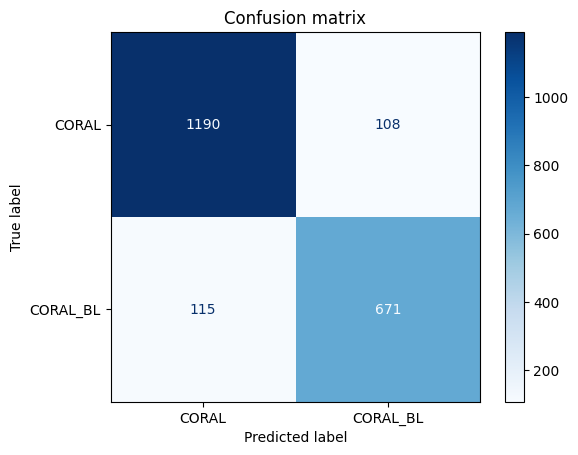

In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(all_true, all_predictions)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues")
plt.title("Confusion matrix")
plt.show()

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


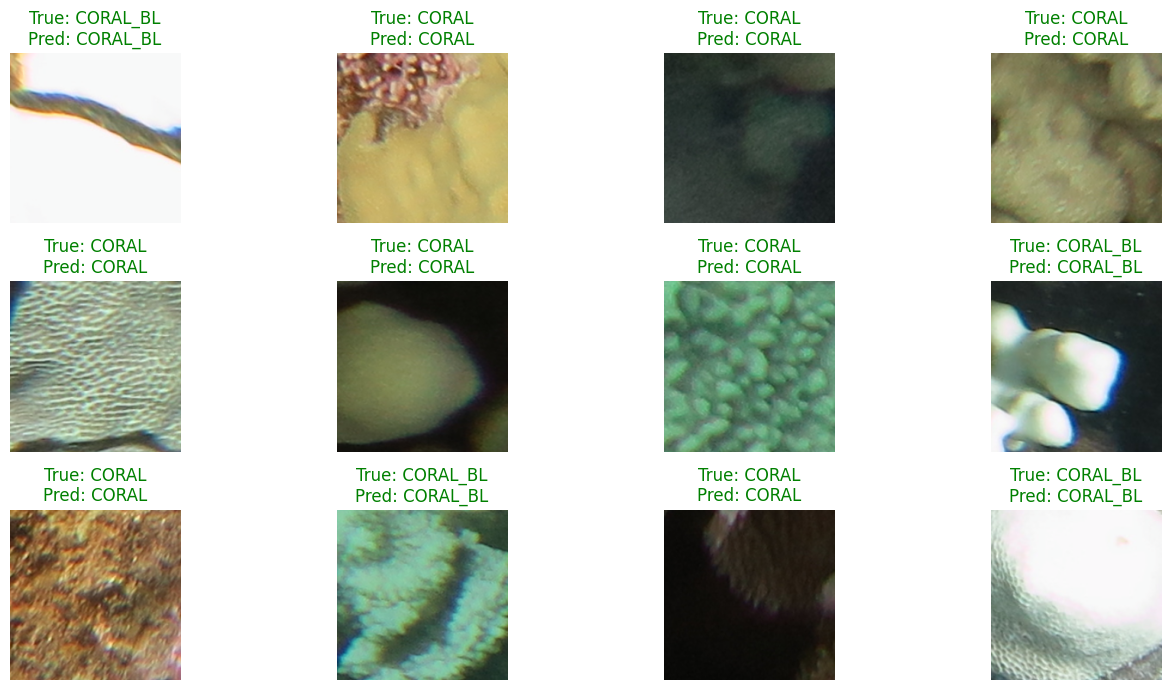

In [18]:
import numpy as np

def show_ready(tensor):
    img = tensor.cpu().permute(1, 2, 0).numpy()
    img = img * np.array(std) + np.array(mean)
    return img.clip(0, 1)

images, labels = next(iter(val_loader))
with torch.no_grad():
    predicted = model(images.to(device)).argmax(dim=1).cpu()

plt.figure(figsize=(14, 7))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.imshow(show_ready(images[i]))
    true_name = class_names[labels[i]]
    pred_name = class_names[predicted[i]]
    color = "green" if true_name == pred_name else "red"
    plt.title(f"True: {true_name}\nPred: {pred_name}", color=color)
    plt.axis("off")
plt.tight_layout()
plt.show()

In [19]:
with open("class_names.txt", "w") as f:
    f.write("\n".join(class_names))

print("Classes:", class_names)

Classes: ['CORAL', 'CORAL_BL']


In [22]:
files.download("best_model.pt")
files.download("class_names.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>